C:\Users\abhis\AppData\Local\Temp\ipykernel_19880\781152970.py:6: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("^NSEI", start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


Shape of dataset:  (19, 5)

Column names:  MultiIndex([( 'Close', '^NSEI'),
            (  'High', '^NSEI'),
            (   'Low', '^NSEI'),
            (  'Open', '^NSEI'),
            ('Volume', '^NSEI')],
           names=['Price', 'Ticker'])

First five rows:  Price              Close          High           Low          Open  Volume
Ticker             ^NSEI         ^NSEI         ^NSEI         ^NSEI   ^NSEI
Date                                                                      
2025-11-03  25763.349609  25803.099609  25645.500000  25696.849609   23300
2025-11-04  25597.650391  25787.400391  25578.400391  25744.750000  305100
2025-11-06  25509.699219  25679.150391  25491.550781  25593.349609  371900
2025-11-07  25492.300781  25551.250000  25318.449219  25433.800781  305600
2025-11-10  25574.349609  25653.449219  25503.500000  25503.500000  243600

Dataframe index:  DatetimeIndex(['2025-11-03', '2025-11-04', '2025-11-06', '2025-11-07',
               '2025-11-10', '2025-11-11', '

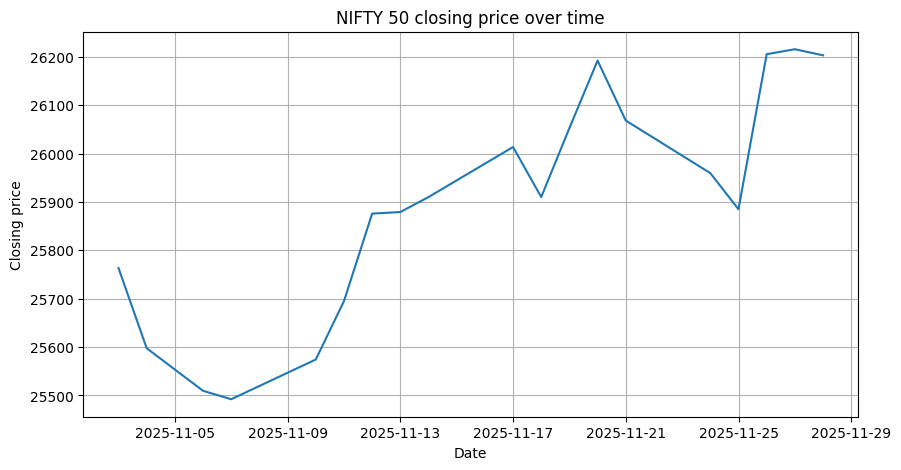

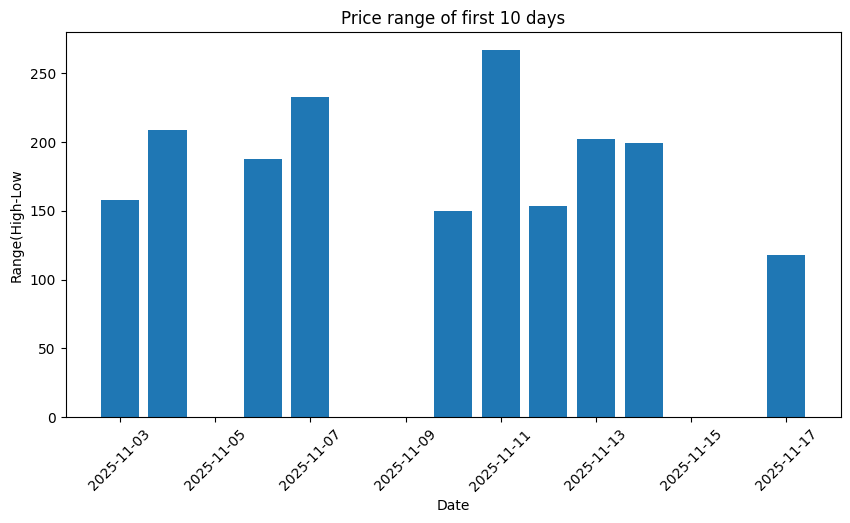

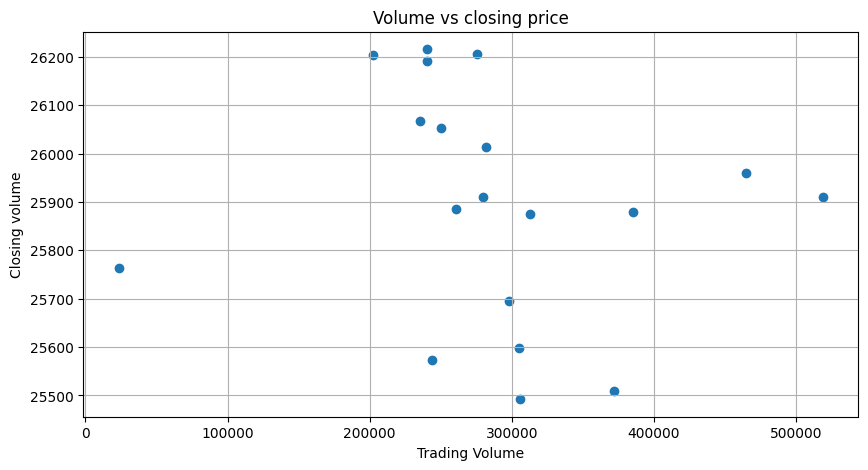


Daily Close change statistics: 
count    18.000000
mean      0.000952
std       0.004931
min      -0.006432
25%      -0.003296
50%       0.000260
75%       0.004534
max       0.012382
Name: Close_change, dtype: float64

MA5 values: 
 Date
2025-11-03             NaN
2025-11-04             NaN
2025-11-06             NaN
2025-11-07             NaN
2025-11-10    25587.469922
2025-11-11    25573.789844
2025-11-12    25629.419922
2025-11-13    25703.310156
2025-11-14    25786.860156
2025-11-17    25874.680078
Name: MA5, dtype: float64

MA10 values: 
 Date
2025-11-03             NaN
2025-11-04             NaN
2025-11-06             NaN
2025-11-07             NaN
2025-11-10             NaN
2025-11-11             NaN
2025-11-12             NaN
2025-11-13             NaN
2025-11-14             NaN
2025-11-17    25731.075000
2025-11-18    25745.745117
2025-11-19    25791.245117
2025-11-20    25859.490234
2025-11-21    25917.075195
2025-11-24    25955.590234
Name: MA10, dtype: float64


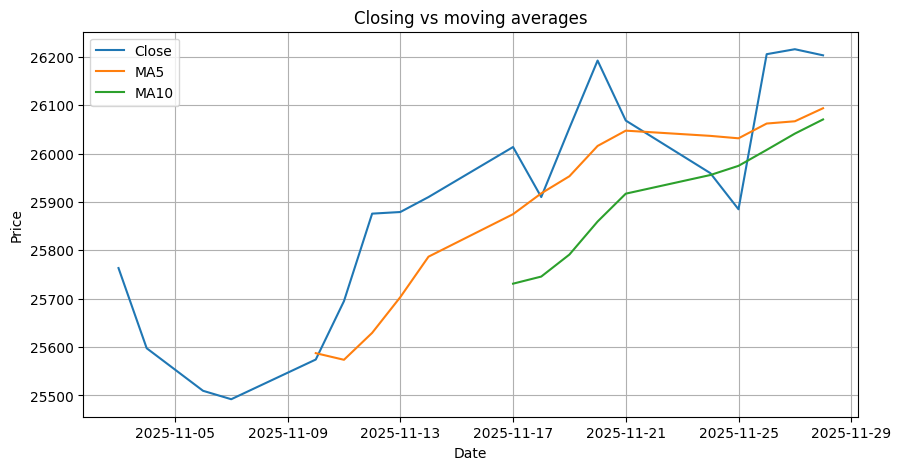

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
start_date = "2025-11-01"
end_date = "2025-12-01"
df = yf.download("^NSEI", start=start_date, end=end_date)
print("Shape of dataset: ", df.shape)
print("\nColumn names: ", df.columns)
print("\nFirst five rows: ",df.head(5) )
print("\nDataframe index: ", df.index)
max_high = df['High'].max()
min_low = df['Low'].min()
print("\nMaximum of High: ", max_high)
print("\nMinimum of low: ", min_low)
df['Range']= df['High']-df['Low']

plt.figure(figsize=(10,5))
plt.plot(df.index, df['Close'])
plt.title("NIFTY 50 closing price over time")
plt.xlabel("Date")
plt.ylabel("Closing price")
plt.grid(True)
plt.show()

plt.figure(figsize=(10,5))
plt.bar(df.index[:10], df['Range'].iloc[:10])
plt.title("Price range of first 10 days")
plt.xlabel("Date")
plt.ylabel("Range(High-Low")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(10,5))
plt.scatter(df['Volume'], df['Close'])
plt.title("Volume vs closing price")
plt.xlabel("Trading Volume")
plt.ylabel("Closing volume")
plt.grid(True)
plt.show()

df['Close_change']=df['Close'].pct_change()
print("\nDaily Close change statistics: ")
print(df['Close_change'].describe())

df['MA5']=df['Close'].rolling(5).mean()
df['MA10']=df['Close'].rolling(10).mean()
print("\nMA5 values: \n", df['MA5'].head(10))
print("\nMA10 values: \n", df['MA10'].head(15))
plt.figure(figsize=(10,5))
plt.plot(df['Close'], label="Close")
plt.plot(df['MA5'], label="MA5")
plt.plot(df['MA10'], label="MA10")
plt.title("Closing vs moving averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()

df.rename(columns={
    "Volume": "traded_volume",
    "Close": "adj_close",
}, inplace = True)

Enter the number of data points(N):  67


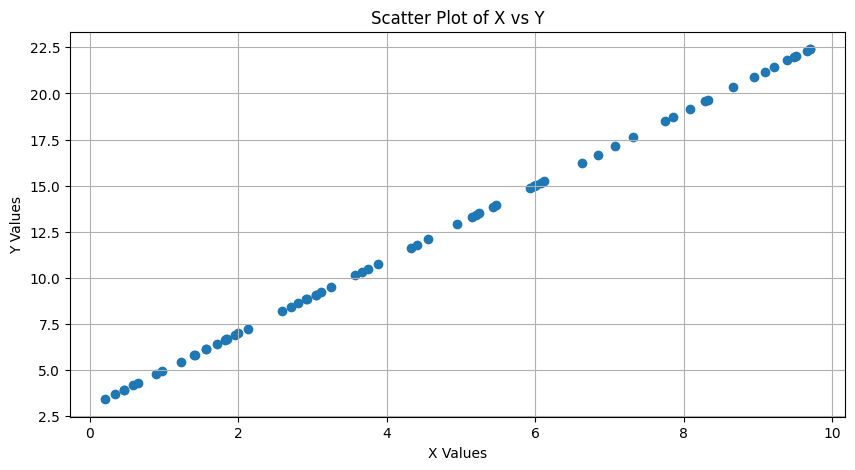

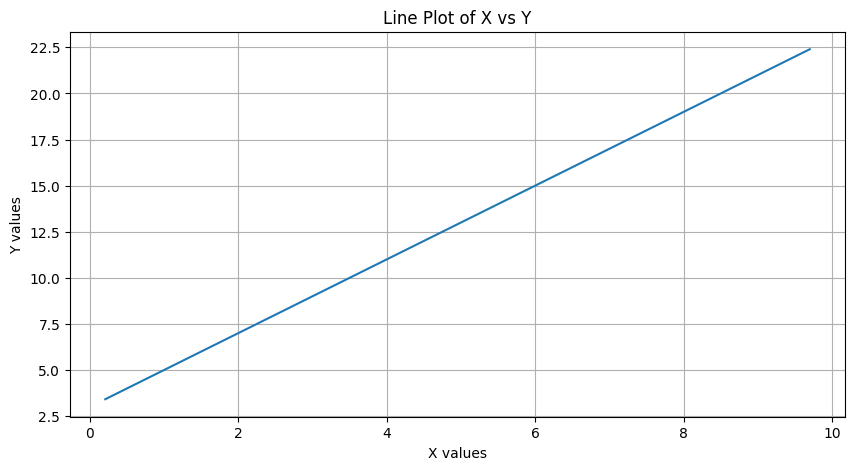

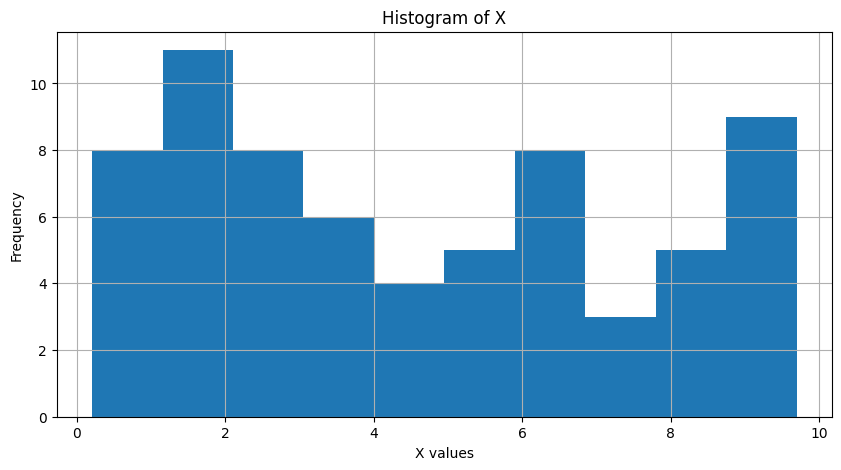

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def generate_data(N):
    X= np.random.uniform(0,10,N)
    Y=2*X+3
    return X, Y

def plot_scatter(X, Y):
    plt.figure(figsize=(10,5))
    plt.scatter(X, Y)
    plt.title("Scatter Plot of X vs Y")
    plt.xlabel("X Values")
    plt.ylabel("Y Values")
    plt.grid(True)
    plt.show()

def plot_line(X, Y):
    sorted_indices=np.argsort(X)
    X_sorted=X[sorted_indices]
    Y_sorted=Y[sorted_indices]
    plt.figure(figsize=(10,5))
    plt.plot(X_sorted, Y_sorted)
    plt.title("Line Plot of X vs Y")
    plt.xlabel("X values")
    plt.ylabel("Y values")
    plt.grid(True)
    plt.show()

def plot_histogram(X):
    plt.figure(figsize=(10,5))
    plt.hist(X, bins=10)
    plt.title("Histogram of X")
    plt.xlabel("X values")
    plt.ylabel("Frequency")
    plt.grid(True)
    plt.show()

def set_seed(seed):
    np.random.seed(seed)

N=int(input("Enter the number of data points(N): "))
set_seed(42)
X, Y = generate_data(N)
plot_scatter(X, Y)
plot_line(X, Y)
plot_histogram(X)

In [5]:
import random


def get_computer_choice():
    return random.choice(["rock", "paper", "scissors"])
def get_winner(user, computer):
    if user==computer:
        return "tie"
    if (user=="rock" and computer=="scissors") or \
            (user=="paper" and computer=="rock") or \
            (user=="scissors" and computer=="paper"):
        return "user"
    else:
        return "computer"

def play_game():
    wins=0
    loses=0
    ties=0
    while True:
        user = input("\nEnter rock, paper, scissors or quit: ").lower()
        if user == "quit":
            print("\nGame Over!")
            print(f"Wins: {wins}, Loses: {loses}, Ties: {ties}")
            break
        if user not in ["rock", "paper", "scissors"]:
            print("Invalid input! Try again.")
            continue
        computer = get_computer_choice()
        print(f"Your choice: {user}")
        print(f"Computer choice: {computer}")
        result= get_winner(user, computer)
        if result=="tie":
            print("It's a tie!")
            ties += 1
        elif result == "user":
            print("You win!")
            wins += 1
        else:
            print("You lose!")
            loses +=1
        print(f"Wins: {wins}, Loses: {loses}, Ties: {ties}")

play_game()



Enter rock, paper, scissors or quit:  rock


Your choice: rock
Computer choice: paper
You lose!
Wins: 0, Loses: 1, Ties: 0



Enter rock, paper, scissors or quit:  ROCK


Your choice: rock
Computer choice: paper
You lose!
Wins: 0, Loses: 2, Ties: 0



Enter rock, paper, scissors or quit:  rock


...

Your choice: rock
Computer choice: rock
It's a tie!
Wins: 0, Loses: 2, Ties: 2



Enter rock, paper, scissors or quit:  paper


Your choice: paper
Computer choice: scissors
You lose!
Wins: 0, Loses: 3, Ties: 2



Enter rock, paper, scissors or quit:  quit



Game Over!
Wins: 0, Loses: 3, Ties: 2


In [6]:
import statistics as stats
def analyze_temperatures(temperatures):
    if len(temperatures)==0:
        print("No temperature data provided.")
        return
    if len(temperatures)==1:
        print("Only one temperature provided.")
        print("Mean: ", temperatures[0])
        print("Median: ", temperatures[0])
        print("Standard Deviation: 0")
        print("Variance: 0")
        return

    mean= stats.mean(temperatures)
    median=stats.median(temperatures)
    std_dev=stats.stdev(temperatures)
    variance= stats.variance(temperatures)
    print("\nTemperature Analysis Results: ")
    print("Mean: ", mean)
    print("Median: ", median)
    print("Standard Deviation: ", std_dev)
    print("Variance: ", variance)

temperatures=[1.2,2.3,3.4,1.9,3.0]
analyze_temperatures(temperatures)


Temperature Analysis Results: 
Mean:  2.36
Median:  2.3
Standard Deviation:  0.8734987120768982
Variance:  0.763
